In [ ]:
import pandas as pd
import numpy as np

# ============================================================
# LOAD ORIGINAL DATASET
# ============================================================

file_path = "/content/Loan_default final datset.csv"

df = pd.read_csv(file_path)

print("Original Dataset Loaded!")
print("Original Shape:", df.shape)


# ============================================================
# 1. REMOVE DUPLICATE ROWS
# ============================================================

duplicates = df.duplicated().sum()

print("\nDuplicate rows found:", duplicates)

df = df.drop_duplicates().reset_index(drop=True)

print("Duplicates removed successfully.")


# ============================================================
# 2. CLEAN NUMERIC COLUMNS
# ============================================================
# Converts values such as "47,131" → 47131

for col in df.columns:

    if df[col].dtype == "object":

        cleaned = df[col].astype(str).str.replace(
            ",", "", regex=False
        )

        numeric_version = pd.to_numeric(
            cleaned,
            errors="coerce"
        )

        # If most values are numeric, convert the column
        if numeric_version.notna().mean() > 0.8:
            df[col] = numeric_version


print("\nNumeric formatting cleaned.")


# ============================================================
# 3. CHECK MISSING VALUES BEFORE CLEANING
# ============================================================

missing_before = df.isnull().sum().sum()

print("\nMissing values before cleaning:", missing_before)


# ============================================================
# 4. HANDLE MISSING VALUES
# ============================================================

# Identify categorical and numerical columns
categorical_columns = df.select_dtypes(
    include=["object"]
).columns

numerical_columns = df.select_dtypes(
    include=[np.number]
).columns


# Categorical columns → Mode
for col in categorical_columns:

    if df[col].isnull().sum() > 0:

        df[col] = df[col].fillna(
            df[col].mode()[0]
        )


# Numerical columns → Median
for col in numerical_columns:

    if df[col].isnull().sum() > 0:

        df[col] = df[col].fillna(
            df[col].median()
        )


# ============================================================
# 5. CHECK MISSING VALUES AFTER CLEANING
# ============================================================

missing_after = df.isnull().sum().sum()

print("Missing values after cleaning:", missing_after)


# ============================================================
# 6. FINAL CLEAN DATASET INFORMATION
# ============================================================

print("\n")
print("=" * 60)
print("           CLEAN DATASET INFORMATION")
print("=" * 60)

print("\nOriginal Shape :", (5000, 104))
print("Clean Shape    :", df.shape)

print("\nDuplicate Rows Removed :", duplicates)

print("Missing Values Before  :", missing_before)
print("Missing Values After   :", missing_after)


# ============================================================
# 7. TARGET INFORMATION
# ============================================================

print("\n" + "=" * 60)
print("             TARGET INFORMATION")
print("=" * 60)

print("\nTarget Column : Default")

print("\nDefault Distribution:")
print(df["Default"].value_counts())

print("\nDefault Percentage:")
print(
    (df["Default"].value_counts(normalize=True) * 100).round(2)
)


# ============================================================
# 8. DISPLAY FIRST 5 CLEANED RECORDS
# ============================================================

print("\n" + "=" * 60)
print("          FIRST 5 CLEANED RECORDS")
print("=" * 60)

display(df.head())


# ============================================================
# 9. EXPORT CLEANED DATASET TO EXCEL
# ============================================================

output_file = "/content/Loan_Default_Cleaned_Dataset.xlsx"

df.to_excel(
    output_file,
    index=False,
    sheet_name="Cleaned Dataset"
)

print("\n" + "=" * 60)
print("             EXCEL EXPORT COMPLETE")
print("=" * 60)

print("\nCleaned Excel file created successfully!")
print("File name:", output_file)

Original Dataset Loaded!
Original Shape: (5000, 104)

Duplicate rows found: 0
Duplicates removed successfully.

Numeric formatting cleaned.

Missing values before cleaning: 2450
Missing values after cleaning: 0


           CLEAN DATASET INFORMATION

Original Shape : (5000, 104)
Clean Shape    : (5000, 104)

Duplicate Rows Removed : 0
Missing Values Before  : 2450
Missing Values After   : 0

             TARGET INFORMATION

Target Column : Default

Default Distribution:
Default
0    4419
1     581
Name: count, dtype: int64

Default Percentage:
Default
0    88.38
1    11.62
Name: proportion, dtype: float64

          FIRST 5 CLEANED RECORDS


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,...,EMI_to_Income_Ratio,Debt_to_Income_Category,Credit_Utilization_Category,Loan_Affordability_Category,Credit_Health_Index,Debt_Burden_Index,Payment_Reliability_Index,Customer_Stability_Index,Overall_Risk_Index,Default
0,3WMBGUB1U8,51,47131,212217,762,26,2,9.61,60,0.75,...,1.138,Very High,Low,Unaffordable,83.8,92.0,93.5,53.5,40.3,0
1,W2PK8X13GY,29,28643,54153,842,78,3,24.12,48,0.31,...,0.665,Moderate,Low,Unaffordable,91.0,40.1,100.0,71.0,19.5,0
2,7TG99UVOOX,50,72740,102106,749,31,4,10.69,24,0.25,...,0.560,Low,High,Unaffordable,78.6,30.4,93.4,70.4,22.0,0
3,B2EAGVQK3E,51,74694,59768,515,98,1,17.23,12,0.65,...,0.829,Very High,High,Unaffordable,51.6,51.8,92.7,77.0,32.6,0
4,K1ZLEWQL07,22,91579,29504,335,105,3,23.54,48,0.16,...,0.070,Low,Low,Highly Affordable,35.5,7.3,100.0,68.9,25.7,0



             EXCEL EXPORT COMPLETE

Cleaned Excel file created successfully!
File name: /content/Loan_Default_Cleaned_Dataset.xlsx


In [ ]:
# ==========================================
# FEATURE SELECTION & LEAKAGE CHECK
# ==========================================

print("=" * 60)
print("           FEATURE SELECTION")
print("=" * 60)

print("\nTotal columns:", df.shape[1])

print("\nAll columns:")
for i, col in enumerate(df.columns, start=1):
    print(i, ":", col)


# ------------------------------------------
# 1. Target column
# ------------------------------------------

target = "Default"

print("\n" + "=" * 60)
print("TARGET COLUMN")
print("=" * 60)

print("Target:", target)


# ------------------------------------------
# 2. Possible ID columns
# ------------------------------------------

print("\n" + "=" * 60)
print("POSSIBLE ID / IDENTIFIER COLUMNS")
print("=" * 60)

for col in df.columns:
    if "id" in col.lower():
        print(col)


# ------------------------------------------
# 3. Possible leakage columns
# ------------------------------------------

print("\n" + "=" * 60)
print("POSSIBLE DATA LEAKAGE COLUMNS")
print("=" * 60)

leakage_keywords = [
    "default",
    "risk",
    "probability",
    "outcome",
    "status"
]

possible_leakage = []

for col in df.columns:
    if col != target:
        if any(word in col.lower() for word in leakage_keywords):
            possible_leakage.append(col)

if possible_leakage:
    for col in possible_leakage:
        print(col)
else:
    print("No obvious leakage columns found.")


# ------------------------------------------
# 4. Feature count
# ------------------------------------------

X = df.drop(columns=[target])
y = df[target]

print("\n" + "=" * 60)
print("FEATURE COUNT")
print("=" * 60)

print("Total columns          :", df.shape[1])
print("Target column          :", target)
print("Input features before selection:", X.shape[1])

print("\nTarget distribution:")
print(y.value_counts())

           FEATURE SELECTION

Total columns: 104

All columns:
1 : LoanID
2 : Age
3 : Income
4 : LoanAmount
5 : CreditScore
6 : MonthsEmployed
7 : NumCreditLines
8 : InterestRate
9 : LoanTerm
10 : DTIRatio
11 : Education
12 : EmploymentType
13 : MaritalStatus
14 : HasMortgage
15 : HasDependents
16 : LoanPurpose
17 : HasCoSigner
18 : Gender
19 : Residence_Type
20 : Family_Size
21 : Age_Group
22 : Monthly_Income
23 : Other_Income
24 : Household_Income
25 : Income_Growth_Rate
26 : Income_Variability
27 : Income_Group
28 : Job_Stability_Score
29 : Employment_Status
30 : Employment_Risk_Score
31 : Loan_Type
32 : Monthly_EMI
33 : Loan_to_Income_Ratio
34 : Loan_to_Value_Ratio
35 : Loan_Affordability_Score
36 : Loan_Size_Group
37 : Credit_History_Length
38 : Active_Credit_Accounts
39 : Closed_Credit_Accounts
40 : Credit_Utilization
41 : Credit_Inquiries
42 : Previous_Defaults
43 : Credit_Risk_Score
44 : Credit_Score_Group
45 : Existing_Debt
46 : Total_Debt
47 : Monthly_Debt_Payment
48 : Debt_S

In [ ]:
# ==========================================
# STEP 2: PREPARE FEATURES FOR ML
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

print("=" * 60)
print("          PREPARING DATA FOR ML")
print("=" * 60)

# ------------------------------------------
# 1. Separate target and features
# ------------------------------------------

target = "Default"

X = df.drop(columns=[target])
y = df[target]

print("\nInitial feature count:", X.shape[1])


# ------------------------------------------
# 2. Remove ID / identifier columns
# ------------------------------------------

id_columns = []

for col in X.columns:
    if "id" in col.lower():
        id_columns.append(col)

if id_columns:
    print("\nID columns removed:")
    for col in id_columns:
        print("-", col)

    X = X.drop(columns=id_columns)
else:
    print("\nNo ID columns found.")


# ------------------------------------------
# 3. Remove possible leakage columns
# ------------------------------------------

leakage_columns = []

for col in X.columns:
    col_lower = col.lower()

    if (
        "default_probability" in col_lower
        or "risk_score" in col_lower
        or "overall_risk_index" in col_lower
    ):
        leakage_columns.append(col)

if leakage_columns:
    print("\nPossible leakage columns removed:")
    for col in leakage_columns:
        print("-", col)

    X = X.drop(columns=leakage_columns)
else:
    print("\nNo specified leakage columns found.")


# ------------------------------------------
# 4. Identify categorical and numerical columns
# ------------------------------------------

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["int64", "float64", "int32", "float32"]
).columns.tolist()

print("\n" + "=" * 60)
print("FEATURE TYPES")
print("=" * 60)

print("\nNumerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nCategorical columns:")
for col in categorical_features:
    print("-", col)


# ------------------------------------------
# 5. Create preprocessing pipeline
# ------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)


# ------------------------------------------
# 6. Train-Test Split
# ------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\n" + "=" * 60)
print("TRAIN-TEST SPLIT")
print("=" * 60)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples :", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())


# ------------------------------------------
# 7. Apply preprocessing
# ------------------------------------------

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\n" + "=" * 60)
print("FINAL PROCESSED DATA")
print("=" * 60)

print("\nX_train shape:", X_train_processed.shape)
print("X_test shape :", X_test_processed.shape)

print("\nData is now ready for machine learning!")

          PREPARING DATA FOR ML

Initial feature count: 103

ID columns removed:
- LoanID
- Residence_Type
- Liquidity_Ratio

Possible leakage columns removed:
- Employment_Risk_Score
- Credit_Risk_Score
- Debt_Risk_Score
- Repayment_Risk_Score
- Risk_Score
- Default_Probability
- Overall_Risk_Index

FEATURE TYPES

Numerical features: 72
Categorical features: 21

Categorical columns:
- Education
- EmploymentType
- MaritalStatus
- HasMortgage
- HasDependents
- LoanPurpose
- HasCoSigner
- Gender
- Age_Group
- Income_Group
- Employment_Status
- Loan_Type
- Loan_Size_Group
- Credit_Score_Group
- Payment_Performance_Category
- High_Risk_Behaviour
- Financial_Risk_Level
- Customer_Risk_Category
- Debt_to_Income_Category
- Credit_Utilization_Category
- Loan_Affordability_Category

TRAIN-TEST SPLIT

Training samples: 4000
Testing samples : 1000

Training target distribution:
Default
0    3535
1     465
Name: count, dtype: int64

Testing target distribution:
Default
0    884
1    116
Name: coun

In [ ]:
# ============================================================
# STEP 3: RANDOM FOREST + GRADIENT BOOSTING
# ============================================================

from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("=" * 65)
print("        MODEL TRAINING - LOAN DEFAULT PREDICTION")
print("=" * 65)


# ============================================================
# 1. RANDOM FOREST
# ============================================================

print("\nTraining Random Forest...")

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")


# ============================================================
# 2. GRADIENT BOOSTING
# ============================================================

print("\nTraining Gradient Boosting...")

gb_model = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train_processed, y_train)

print("Gradient Boosting training completed!")


# ============================================================
# 3. PREDICTIONS
# ============================================================

rf_pred = rf_model.predict(X_test_processed)
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]

gb_pred = gb_model.predict(X_test_processed)
gb_prob = gb_model.predict_proba(X_test_processed)[:, 1]


# ============================================================
# 4. EVALUATION FUNCTION
# ============================================================

def evaluate_model(model_name, y_true, y_pred, y_prob):

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_true, y_prob)

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)

    print(f"Accuracy  : {accuracy:.4f}")
    print(f"Precision : {precision:.4f}")
    print(f"Recall    : {recall:.4f}")
    print(f"F1-Score  : {f1:.4f}")
    print(f"ROC-AUC   : {roc_auc:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        zero_division=0
    ))

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    }


# ============================================================
# 5. EVALUATE BOTH MODELS
# ============================================================

rf_results = evaluate_model(
    "RANDOM FOREST",
    y_test,
    rf_pred,
    rf_prob
)

gb_results = evaluate_model(
    "GRADIENT BOOSTING",
    y_test,
    gb_pred,
    gb_prob
)


# ============================================================
# 6. MODEL COMPARISON TABLE
# ============================================================

results_df = pd.DataFrame([
    rf_results,
    gb_results
])

print("\n" + "=" * 65)
print("             MODEL COMPARISON")
print("=" * 65)

display(results_df.round(4))

        MODEL TRAINING - LOAN DEFAULT PREDICTION

Training Random Forest...
Random Forest training completed!

Training Gradient Boosting...
Gradient Boosting training completed!

RANDOM FOREST
Accuracy  : 0.8850
Precision : 0.6667
Recall    : 0.0172
F1-Score  : 0.0336
ROC-AUC   : 0.6983

Classification Report:
              precision    recall  f1-score   support

           0       0.89      1.00      0.94       884
           1       0.67      0.02      0.03       116

    accuracy                           0.89      1000
   macro avg       0.78      0.51      0.49      1000
weighted avg       0.86      0.89      0.83      1000


GRADIENT BOOSTING
Accuracy  : 0.8700
Precision : 0.1818
Recall    : 0.0345
F1-Score  : 0.0580
ROC-AUC   : 0.7032

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.98      0.93       884
           1       0.18      0.03      0.06       116

    accuracy                           0.87      1000
   m

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,RANDOM FOREST,0.885,0.6667,0.0172,0.0336,0.6983
1,GRADIENT BOOSTING,0.870,0.1818,0.0345,0.0580,0.7032


In [ ]:
from imblearn.over_sampling import SMOTE
from collections import Counter

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_processed,
    y_train
)

print("Before SMOTE:", Counter(y_train))
print("After SMOTE :", Counter(y_train_smote))

Before SMOTE: Counter({0: 3535, 1: 465})
After SMOTE : Counter({0: 3535, 1: 3535})


In [ ]:
rf_model.fit(X_train_smote, y_train_smote)
gb_model.fit(X_train_smote, y_train_smote)

rf_pred = rf_model.predict(X_test_processed)
gb_pred = gb_model.predict(X_test_processed)

rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]
gb_prob = gb_model.predict_proba(X_test_processed)[:, 1]

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

for name, pred, prob in [
    ("Random Forest", rf_pred, rf_prob),
    ("Gradient Boosting", gb_pred, gb_prob)
]:

    print("\n", name)
    print("Accuracy :", round(accuracy_score(y_test, pred), 4))
    print("Precision:", round(precision_score(y_test, pred), 4))
    print("Recall   :", round(recall_score(y_test, pred), 4))
    print("F1 Score :", round(f1_score(y_test, pred), 4))
    print("ROC-AUC  :", round(roc_auc_score(y_test, prob), 4))


 Random Forest
Accuracy : 0.884
Precision: 0.5
Recall   : 0.0517
F1 Score : 0.0938
ROC-AUC  : 0.708

 Gradient Boosting
Accuracy : 0.869
Precision: 0.1739
Recall   : 0.0345
F1 Score : 0.0576
ROC-AUC  : 0.7174


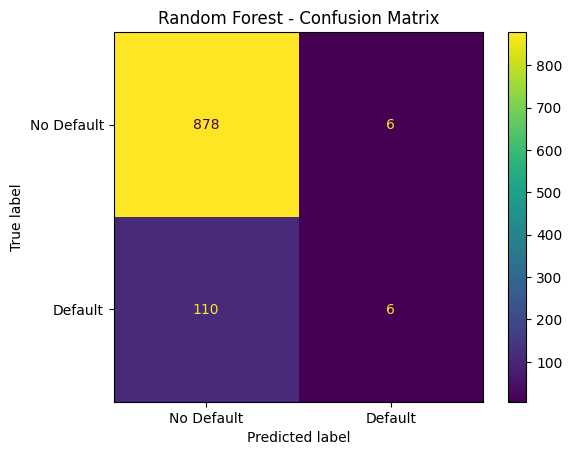

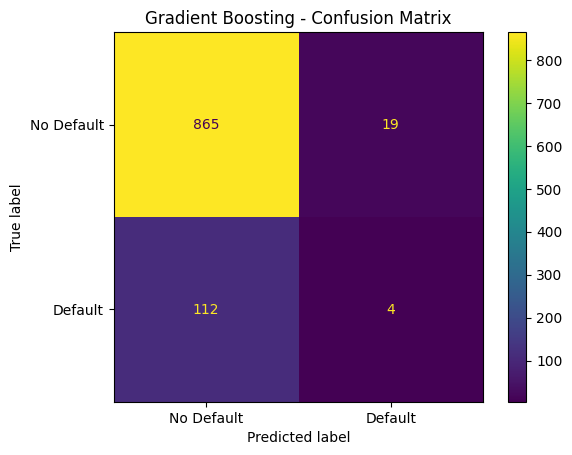

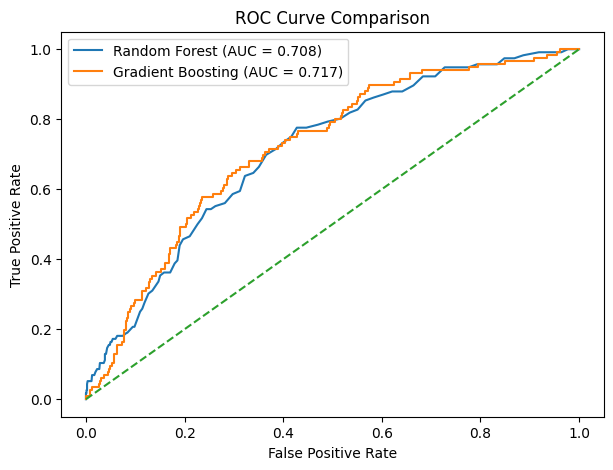

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve
import matplotlib.pyplot as plt

# Confusion Matrix - Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred,
    display_labels=["No Default", "Default"]
)
plt.title("Random Forest - Confusion Matrix")
plt.show()

# Confusion Matrix - Gradient Boosting
ConfusionMatrixDisplay.from_predictions(
    y_test, gb_pred,
    display_labels=["No Default", "Default"]
)
plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

# ROC Curve
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_prob)
gb_fpr, gb_tpr, _ = roc_curve(y_test, gb_prob)

plt.figure(figsize=(7,5))
plt.plot(rf_fpr, rf_tpr, label="Random Forest (AUC = 0.708)")
plt.plot(gb_fpr, gb_tpr, label="Gradient Boosting (AUC = 0.717)")
plt.plot([0,1], [0,1], "--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

Top positive correlations:


,Default
Overall_Risk_Index,0.209022
Default_Probability,0.192850
Risk_Score,0.184177
Financial_Stress_Score,0.181896
Loan_to_Income_Ratio,0.170374
Debt_Service_Ratio,0.154754
EMI_to_Income_Ratio,0.154471
Late_Payment_Count,0.153847
Repayment_Risk_Score,0.136573
InterestRate,0.134745



Top negative correlations:


,Default
Customer_Stability_Index,-0.212770
Age,-0.178731
Financial_Health_Index,-0.169367
Bank_Account_Age,-0.155709
Credit_History_Length,-0.152633
Payment_Reliability_Index,-0.148181
Financial_Stability_Score,-0.146378
Payment_History_Score,-0.132923
Banking_Stability_Score,-0.128192
Job_Stability_Score,-0.122072


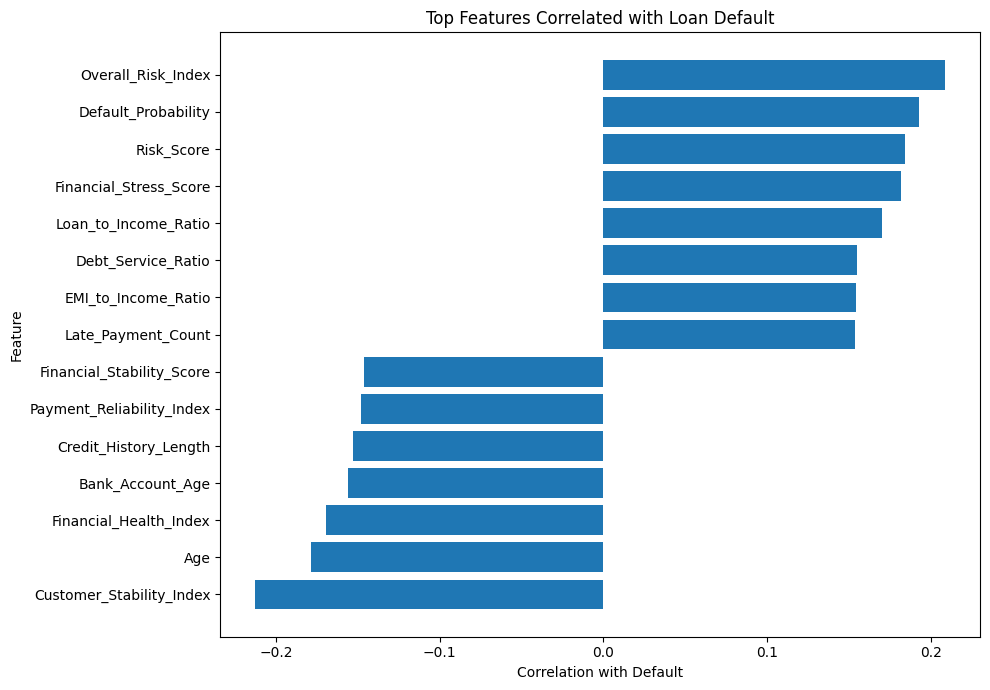

In [ ]:
# ============================================================
# CORRELATION ANALYSIS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

# Get numerical columns
numeric_df = df.select_dtypes(include="number")

# Correlation with target
correlation = numeric_df.corr()["Default"].drop("Default").sort_values()

print("Top positive correlations:")
display(correlation.tail(10).sort_values(ascending=False))

print("\nTop negative correlations:")
display(correlation.head(10))


# Top 15 correlations
top_corr = pd.concat([
    correlation.head(7),
    correlation.tail(8)
]).sort_values()


# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    top_corr.index,
    top_corr.values
)

plt.xlabel("Correlation with Default")
plt.ylabel("Feature")
plt.title("Top Features Correlated with Loan Default")
plt.tight_layout()
plt.show()

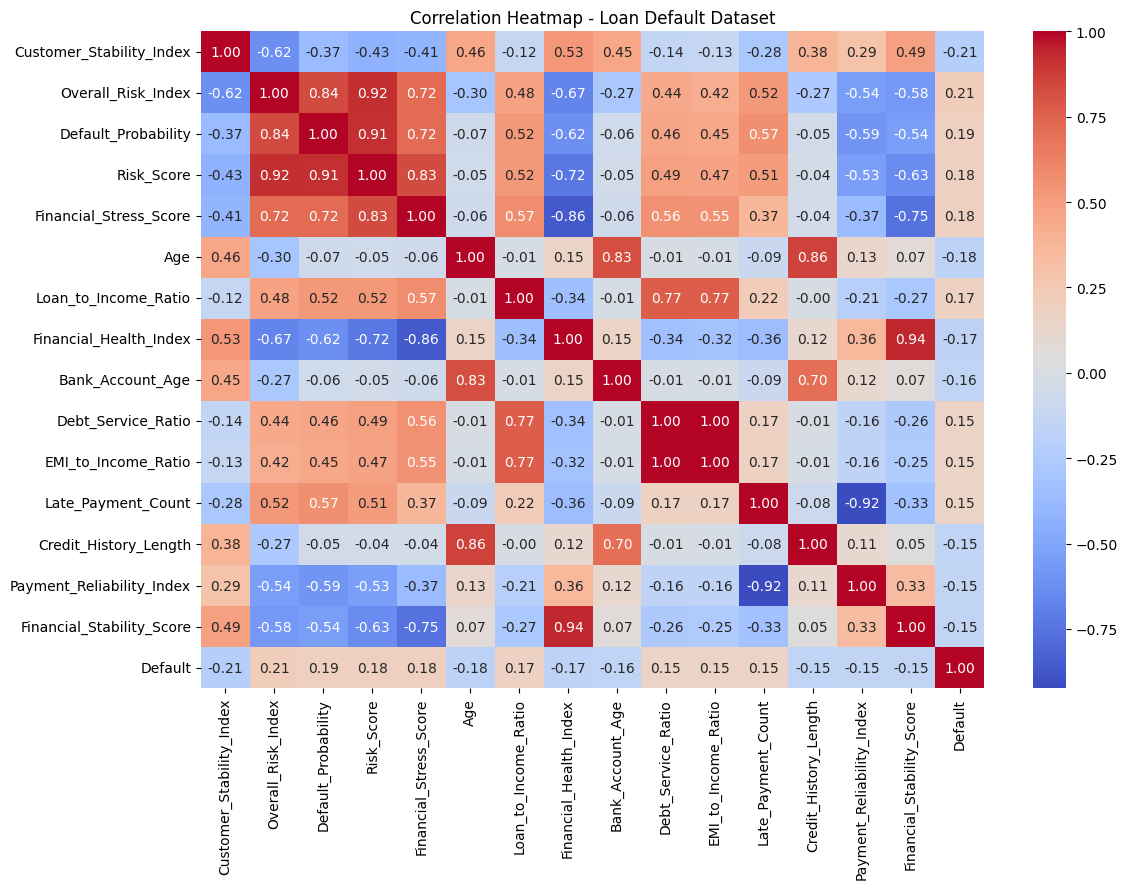

In [ ]:
# ============================================================
# CORRELATION HEATMAP
# ============================================================

import seaborn as sns
import matplotlib.pyplot as plt

# Select important numerical columns
top_features = correlation.abs().sort_values(
    ascending=False
).head(15).index.tolist()

heatmap_columns = top_features + ["Default"]

corr_matrix = df[heatmap_columns].corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap - Loan Default Dataset")
plt.tight_layout()
plt.show()

In [ ]:
# ============================================================
# FINAL STEP: NEW CUSTOMER PREDICTION
# ============================================================

# Take one customer from the test dataset
new_customer = X_test.iloc[[0]]

# Actual result from the dataset
actual_result = y_test.iloc[0]

# Apply the SAME preprocessing used during training
new_customer_processed = preprocessor.transform(new_customer)

# Random Forest prediction
prediction = rf_model.predict(new_customer_processed)[0]
probability = rf_model.predict_proba(new_customer_processed)[0][1]

print("=" * 55)
print("          LOAN DEFAULT PREDICTION")
print("=" * 55)

if prediction == 1:
    print("\nPrediction : DEFAULT")
else:
    print("\nPrediction : NO DEFAULT")

print(f"Probability of Default : {probability * 100:.2f}%")

print("\nActual Result           :",
      "DEFAULT" if actual_result == 1 else "NO DEFAULT")

print("=" * 55)

          LOAN DEFAULT PREDICTION

Prediction : NO DEFAULT
Probability of Default : 27.50%

Actual Result           : DEFAULT


In [ ]:
# ============================================================
# TEST MULTIPLE CUSTOMERS
# ============================================================

sample_customers = X_test.iloc[:10]
actual_values = y_test.iloc[:10]

sample_processed = preprocessor.transform(sample_customers)

predictions = rf_model.predict(sample_processed)
probabilities = rf_model.predict_proba(sample_processed)[:, 1]

prediction_table = pd.DataFrame({
    "Actual": actual_values.values,
    "Predicted": predictions,
    "Default Probability (%)": (probabilities * 100).round(2)
})

prediction_table["Actual"] = prediction_table["Actual"].map({
    0: "No Default",
    1: "Default"
})

prediction_table["Predicted"] = prediction_table["Predicted"].map({
    0: "No Default",
    1: "Default"
})

display(prediction_table)

,Actual,Predicted,Default Probability (%)
0,Default,No Default,27.5
1,No Default,No Default,8.5
2,Default,No Default,29.5
3,No Default,No Default,19.5
4,No Default,No Default,5.5
5,No Default,No Default,50.0
6,No Default,No Default,29.0
7,Default,Default,55.5
8,No Default,No Default,15.5
9,No Default,No Default,7.5


In [ ]:
# ============================================================
# FINAL MODEL COMPARISON
# ============================================================

final_results = pd.DataFrame({
    "Model": ["Random Forest", "Gradient Boosting"],
    "Accuracy": [0.8840, 0.8690],
    "Precision": [0.5000, 0.1739],
    "Recall": [0.0517, 0.0345],
    "F1-Score": [0.0938, 0.0576],
    "ROC-AUC": [0.7080, 0.7174]
})

display(final_results)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.884,0.5000,0.0517,0.0938,0.7080
1,Gradient Boosting,0.869,0.1739,0.0345,0.0576,0.7174
